## Setup

In [1]:
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig3_path = "/content/drive/My Drive/fig3_education_of_neet_2026.png"  # where the education chart is saved on Drive

## Mount Google Drive

In [2]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Mounted at /content/drive


## Load the data

In [3]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Table 3: 2026 Education of NEET people by age group and sex

In [4]:
dummies = {  # education dummies and their labels, in order
    "less_hs": "Less than high school",  # lowest level
    "hs_ged": "High school or GED",  # high school diploma or GED
    "some_college": "Some college",  # some college
    "bachelor_plus": "Bachelor or higher",  # highest level
}  # end of dummies
age_vars = {"16-19": "age16_19", "20-24": "age20_24", "25-29": "age25_29"}  # age-group dummies from the cleaned data
sexes = {"Men": 0, "Women": 1}  # female = 0 for Men, 1 for Women

neet26 = df[(df["year"] == 2026) & (df["neet"] == 1)].copy()  # keep only 2026 and only NEET people
n_left_out = neet26[list(dummies)].isna().any(axis=1).sum()  # NEET people with missing education
known = neet26.dropna(subset=list(dummies))  # leave them out

# empty tables, filled in below: one row per age group and sex, Men before Women
row_labels = [f"{age} {sex}" for age in age_vars for sex in sexes]  # the six rows
table = pd.DataFrame(0.0, index=row_labels, columns=list(dummies.values()))  # weighted percent
people = pd.DataFrame(0, index=row_labels, columns=list(dummies.values()))  # unweighted respondents

for age, age_var in age_vars.items():  # loop over the age groups
    for sex, female in sexes.items():  # Men first, then Women
        group = known[(known[age_var] == 1) & (known["female"] == female)]  # NEET people in this row
        row = f"{age} {sex}"  # row label, e.g. "16-19 Men"
        total_weight = group["asecwt"].sum()  # weighted number of NEET people in this row
        for var, label in dummies.items():  # loop over the four education dummies
            table.loc[row, label] = (group[var] * group["asecwt"]).sum() / total_weight * 100  # weighted percent
            people.loc[row, label] = (group[var] == 1).sum()  # unweighted respondents with this education

def star(count):  # an asterisk if fewer than 30 respondents, otherwise a space
    return "*" if count < 30 else " "  # the asterisk or a space

shown = table.map("{:.1f}".format) + people.map(star)  # percent with 1 decimal, then the asterisk or a space

distance_from_100 = (table.sum(axis=1) - 100).abs()  # distance from 100 in each row, before rounding

print("NEET people in 2026 left out because education is missing (unweighted):", n_left_out)  # how many were left out
print()  # empty line
print("Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt).")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks
print("* fewer than 30 unweighted respondents")  # key for the asterisk
print()  # empty line
print("Check: every row adds up to 100.0:", bool((distance_from_100 < 1e-9).all()))  # True or False
print("Largest distance from 100 in any row (before rounding):", distance_from_100.max())  # should be about 0
print()  # empty line
print("Unweighted number of respondents in each cell.")  # counts title
print(people.to_string())  # counts, same layout

NEET people in 2026 left out because education is missing (unweighted): 0

Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt).
            Less than high school High school or GED Some college Bachelor or higher
16-19 Men                   39.0               54.9          5.8*               0.3*
16-19 Women                 42.2               45.5         12.1*               0.3*
20-24 Men                   21.0               56.4         15.4                7.2 
20-24 Women                 17.1               54.5         17.9               10.5 
25-29 Men                   12.8               46.4         22.9               17.9 
25-29 Women                 13.0               45.3         19.5               22.2 
* fewer than 30 unweighted respondents

Check: every row adds up to 100.0: True
Largest distance from 100 in any row (before rounding): 2.842170943040401e-14

Unweighted number of respondents in each cell.
             Less than high 

**What one cell means.** Take the row "20-24 Women" and the column "Some college". Among women aged 20-24 in the 2026 survey who were NEET (not employed and not in school) and whose education is known, the cell is the percent who had some college. Each row adds up to 100, so the cells show how NEET people in that row are split across the four education levels. This is a share of NEET people, not a share of all women aged 20-24, so it is not a NEET rate. People are counted by how many people in the country they represent (`asecwt`). An asterisk marks a cell with fewer than 30 survey respondents behind it, shown in the count table under the table.

## Figure 3: Education of NEET people by age group and sex, 2026

Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt). Figure 3 shows this table.
            Less than high school High school or GED Some college Bachelor or higher
16-19 Men                   39.0               54.9          5.8*               0.3*
16-19 Women                 42.2               45.5         12.1*               0.3*
20-24 Men                   21.0               56.4         15.4                7.2 
20-24 Women                 17.1               54.5         17.9               10.5 
25-29 Men                   12.8               46.4         22.9               17.9 
25-29 Women                 13.0               45.3         19.5               22.2 
* fewer than 30 unweighted respondents


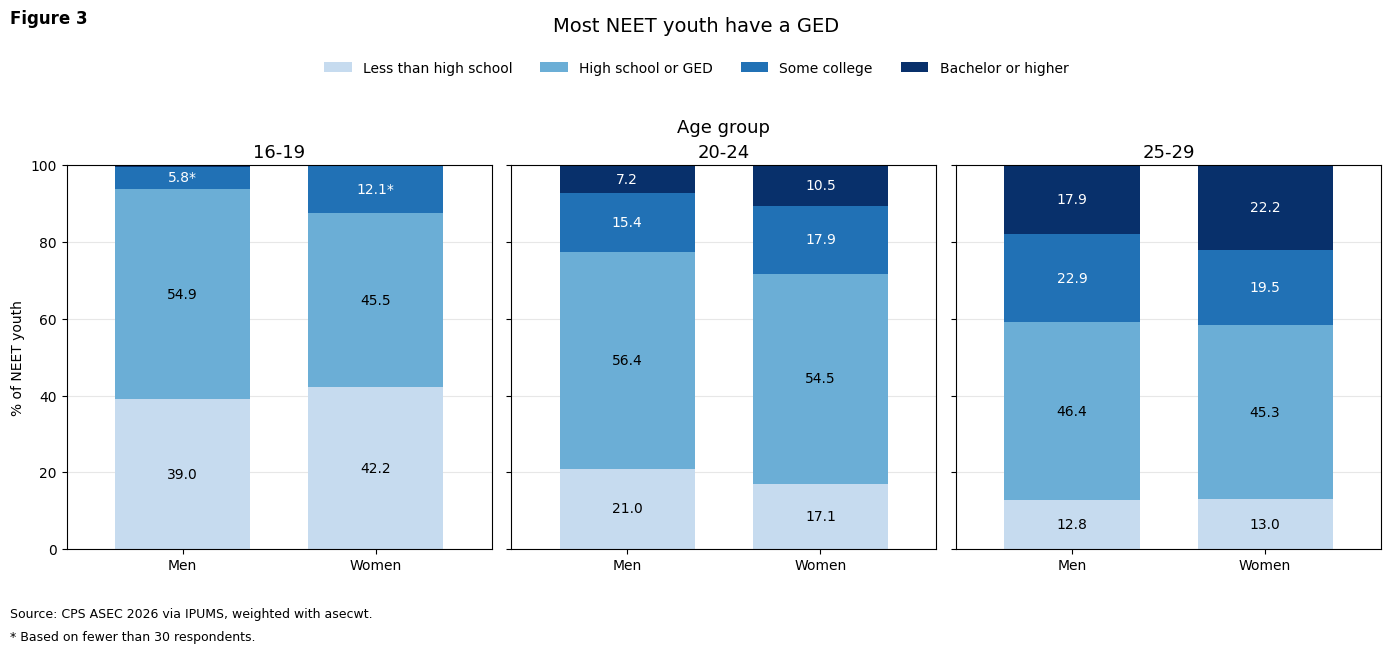

In [6]:
chart_title = "Most NEET youth have a GED"  # chart title

print("Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt). Figure 3 shows this table.")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks
print("* fewer than 30 unweighted respondents")  # key for the asterisk

# settings
colors = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]  # four shades of blue, light = lowest education, dark = highest
text_colors = ["black", "black", "white", "white"]  # number color inside each segment
asterisk_shown = ((table >= 3.0) & (people < 30)).any().any()  # True if a labeled segment has fewer than 30 respondents

# one panel for each age group, with a stacked bar for Men and one for Women
fig, axes = plt.subplots(1, 3, figsize=(14, 6.5), sharey=True)  # three panels, same y-axis
for ax, age in zip(axes, age_vars):  # one panel per age group
    for x, sex in enumerate(sexes):  # Men first, then Women, next to each other
        row = f"{age} {sex}"  # row label in the table
        bottom = 0  # where the next segment starts
        for i, column in enumerate(table.columns):  # stack from the lowest education level to the highest
            value = table.loc[row, column]  # percent for this segment
            ax.bar(x, value, bottom=bottom, width=0.7, color=colors[i], label=column)  # one segment
            if value >= 3.0:  # label only segments of 3.0% or more
                text = f"{value:.1f}" + ("*" if people.loc[row, column] < 30 else "")  # value, plus an asterisk if fewer than 30
                ax.text(x, bottom + value / 2, text, ha="center", va="center", color=text_colors[i], fontsize=10)  # value inside the segment
            bottom = bottom + value  # next segment starts on top of this one
    ax.set_title(age, fontsize=13)  # panel title is the age group
    ax.set_xticks([0, 1])  # one tick under each bar
    ax.set_xticklabels(["Men", "Women"])  # Men and Women under each bar
    ax.set_xlim(-0.6, 1.6)  # room on both sides
    ax.set_ylim(0, 100)  # y-axis from 0 to 100
    ax.set_yticks(range(0, 101, 20))  # y ticks every 20
    ax.grid(True, axis="y", alpha=0.3)  # light grid behind the bars
    ax.set_axisbelow(True)  # grid lines behind the bars
axes[0].set_ylabel("% of NEET youth")  # y-axis label (shared by all panels)

# legend, title and notes
handles, labels = axes[0].get_legend_handles_labels()  # every segment has a label, the first four are the four education levels
fig.legend(handles[:4], labels[:4], loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=4, frameon=False)  # one legend for all panels
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 3", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.1, 1, 0.86])  # leave room for the title, legend, heading and notes
middle = axes[1].get_position()  # position of the middle panel (20-24)
heading_x = (middle.x0 + middle.x1) / 2  # horizontal center of the middle panel
fig.text(heading_x, middle.y1 + 0.045, "Age group", ha="center", va="bottom", fontsize=13)  # one heading above the panels
fig.text(0.01, 0.055, "Source: CPS ASEC 2026 via IPUMS, weighted with asecwt.", fontsize=9)  # source note
if asterisk_shown:  # only if an asterisk appears on the chart
    fig.text(0.01, 0.02, "* Based on fewer than 30 respondents.", fontsize=9)  # required note

# save and show
fig.savefig(fig3_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding: